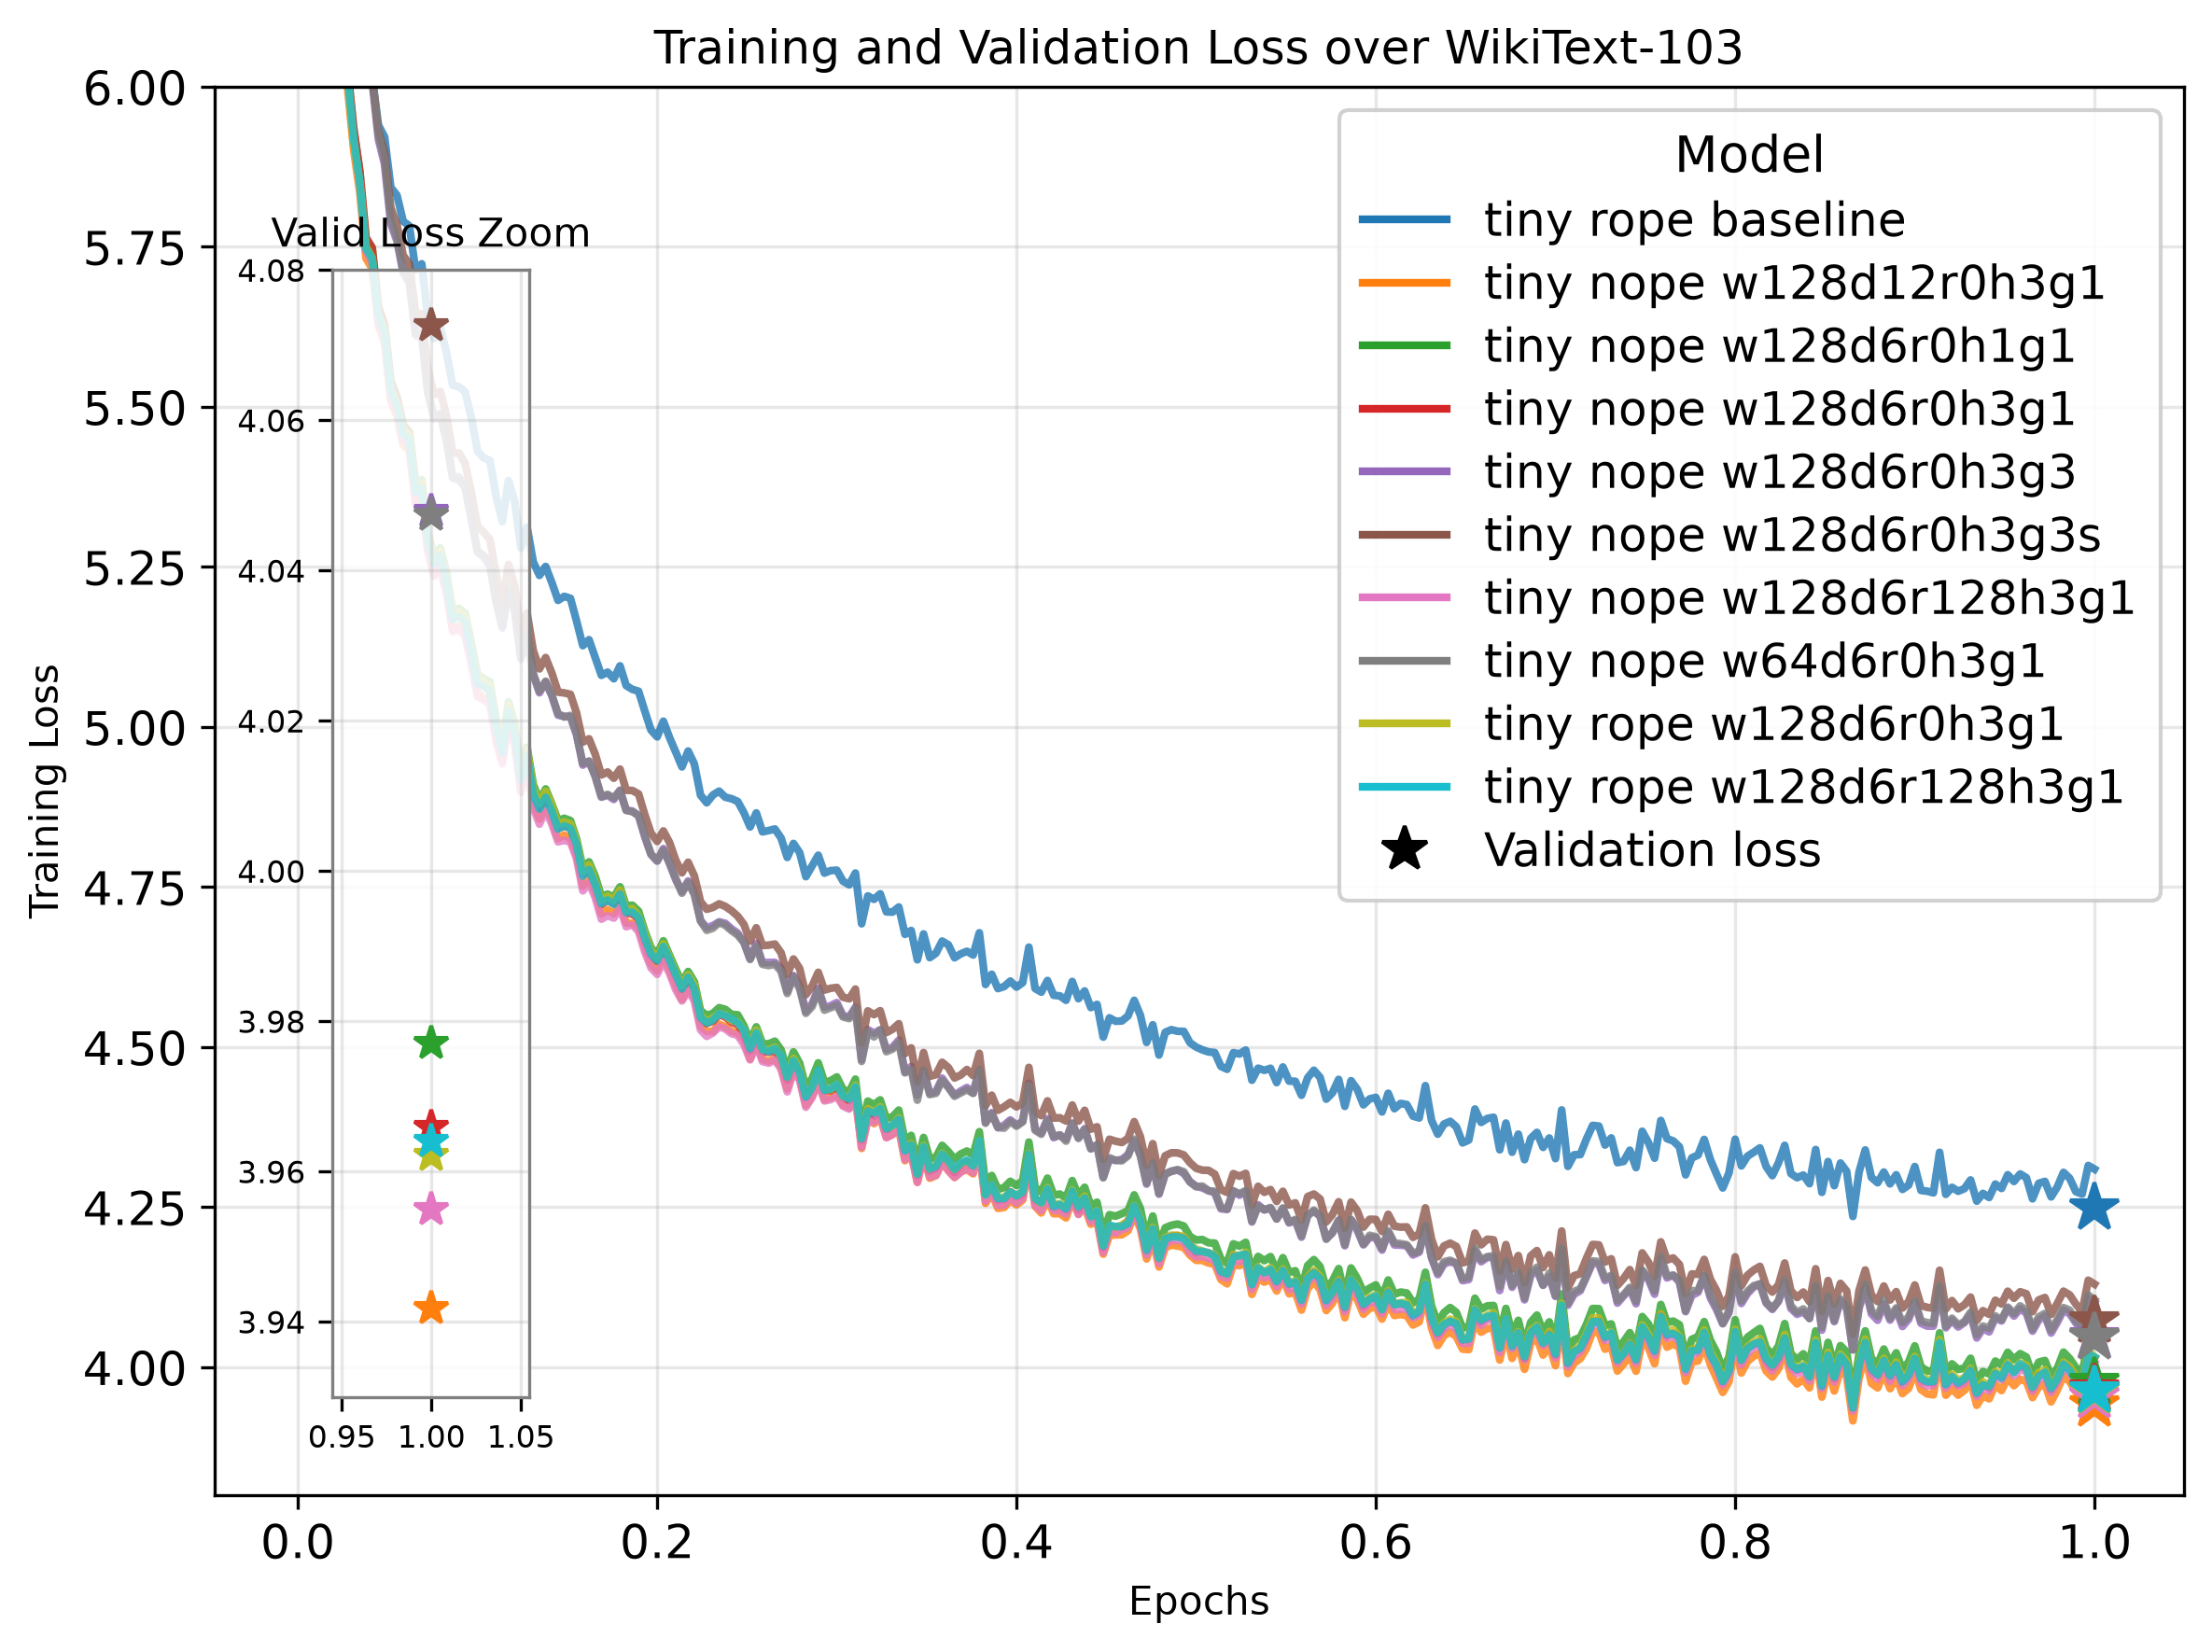

In [15]:
import os, re
import json
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOTS = ["results"]


def name_to_label(name):
    parts = name.split("_")
    base = " ".join(parts[0:-1]) if len(parts) > 1 else name
    return {}.get(base, base)


def read_trainer_state(ckpt_dir):
    path = os.path.join(ckpt_dir, "trainer_state.json")
    if not os.path.isfile(path):
        return None
    with open(path) as f:
        return json.load(f)


def read_eval_results(ckpt_dir):
    path = os.path.join(ckpt_dir, "../eval_results.txt")
    if not os.path.isfile(path):
        return None
    with open(path) as f:
        text = f.read()
    m = re.search(r"loss\s*=\s*([\d.]+)", text)
    return float(m.group(1)) if m else None


def find_latest_checkpoint(folder):
    ckpts = sorted(
        (int(m.group(1)), d)
        for d in os.listdir(folder)
        if (m := re.fullmatch(r"checkpoint-(\d+)", d))
        and os.path.isdir(os.path.join(folder, d))
    )
    return ckpts[-1][1] if ckpts else None


def find_latest_state(folder):
    ckpt = find_latest_checkpoint(folder)
    if ckpt is None:
        return None
    return read_trainer_state(os.path.join(folder, ckpt))


# ---------- 自动收集所有候选文件夹 ----------
folders = []
for root in ROOTS:
    if not os.path.isdir(root):
        print(f"[WARN] 根目录不存在: {root}")
        continue
    folders += sorted(
        os.path.join(root, d)
        for d in os.listdir(root)
        if os.path.isdir(os.path.join(root, d)) and not d.startswith(".")
    )

# 按字符排序，含 "baseline" 的排最上面
folders = sorted(
    folders,
    key=lambda p: (0 if "baseline" in os.path.basename(p).lower() else 1, p),
)

if not folders:
    raise SystemExit("没有找到任何候选文件夹，请检查 ROOTS 设置。")

# ---------- 绘图 ----------
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

model_handles, model_labels = [], []
eval_records = []  # [(label, color, [(epoch, eval_loss), ...]), ...]

for folder in folders:
    folder = folder.rstrip("/")
    name = os.path.basename(folder)
    if not name.startswith("tiny"):
        continue
    label = name_to_label(name)

    state = find_latest_state(folder)
    if not state:
        continue

    train_pts = sorted(
        (e["epoch"], e["loss"])
        for e in state.get("log_history", [])
        if "loss" in e and "eval_loss" not in e and "epoch" in e
    )
    if not train_pts:
        continue

    color = colors[len(model_handles) % len(colors)]
    ax.plot(
        [p[0] for p in train_pts],
        [p[1] for p in train_pts],
        lw=2.0,
        alpha=0.8,
        color=color,
        linestyle="-",
    )

    # eval loss 点（同色星星）
    eval_pts = sorted(
        (e["epoch"], e["eval_loss"])
        for e in state.get("log_history", [])
        if "eval_loss" in e and "epoch" in e
    )
    if not eval_pts:
        ckpt = find_latest_checkpoint(folder)
        ev = read_eval_results(os.path.join(folder, ckpt)) if ckpt else None
        if ev is not None:
            eval_pts = [(train_pts[-1][0], ev)]

    if eval_pts:
        ax.plot(
            [p[0] for p in eval_pts],
            [p[1] for p in eval_pts],
            linestyle="none",
            marker="*",
            markersize=13,
            color=color,
            zorder=5,
        )
        eval_records.append((label, color, eval_pts))

    model_handles.append(Line2D([0], [0], color=color, lw=2.0))
    model_labels.append(label)

if not model_handles:
    raise SystemExit("所有文件夹都没有可用数据，未绘制任何曲线。")

# ---------- 左下角 inset：放大 validation loss ----------
if eval_records:
    # [x0, y0, width, height] 相对于主图 axes (0~1)，左下角
    inset = ax.inset_axes([0.06, 0.07, 0.1, 0.8])

    for label, color, pts in eval_records:
        xs = [p[0] for p in pts]
        ys = [p[1] for p in pts]
        if len(pts) >= 2:
            inset.plot(xs, ys, lw=1.2, alpha=0.5, color=color, zorder=2)
        inset.plot(
            xs, ys, linestyle="none", marker="*", markersize=9, color=color, zorder=5
        )

    inset.set_title("Valid Loss Zoom", fontsize=10)
    inset.tick_params(labelsize=8)
    inset.grid(True, alpha=0.3)
    for spine in inset.spines.values():
        spine.set_edgecolor("gray")

    # 半透明白底，避免主图曲线透过
    inset.patch.set_facecolor("white")
    inset.patch.set_alpha(0.85)

    inset.set_ylim(3.93, 4.08)

# ---------- 图例 ----------
legend_handles = model_handles + [
    Line2D([0], [0], color="black", linestyle="none", marker="*", markersize=12)
]
legend_labels = model_labels + ["Validation loss"]

ax.legend(
    handles=legend_handles,
    labels=legend_labels,
    loc="upper right",
    title="Model",
    fontsize=12,
    framealpha=0.9,
    labelspacing=0.35,
    handlelength=1.8,
    borderpad=0.5,
    title_fontsize=13,
)

ax.set_xlabel("Epochs")
ax.set_ylabel("Training Loss")
ax.set_title("Training and Validation Loss over WikiText-103")
ax.set_ylim(3.8, 6)
ax.tick_params(labelsize=12)
ax.grid(True, alpha=0.3)
fig.tight_layout()

plt.show()

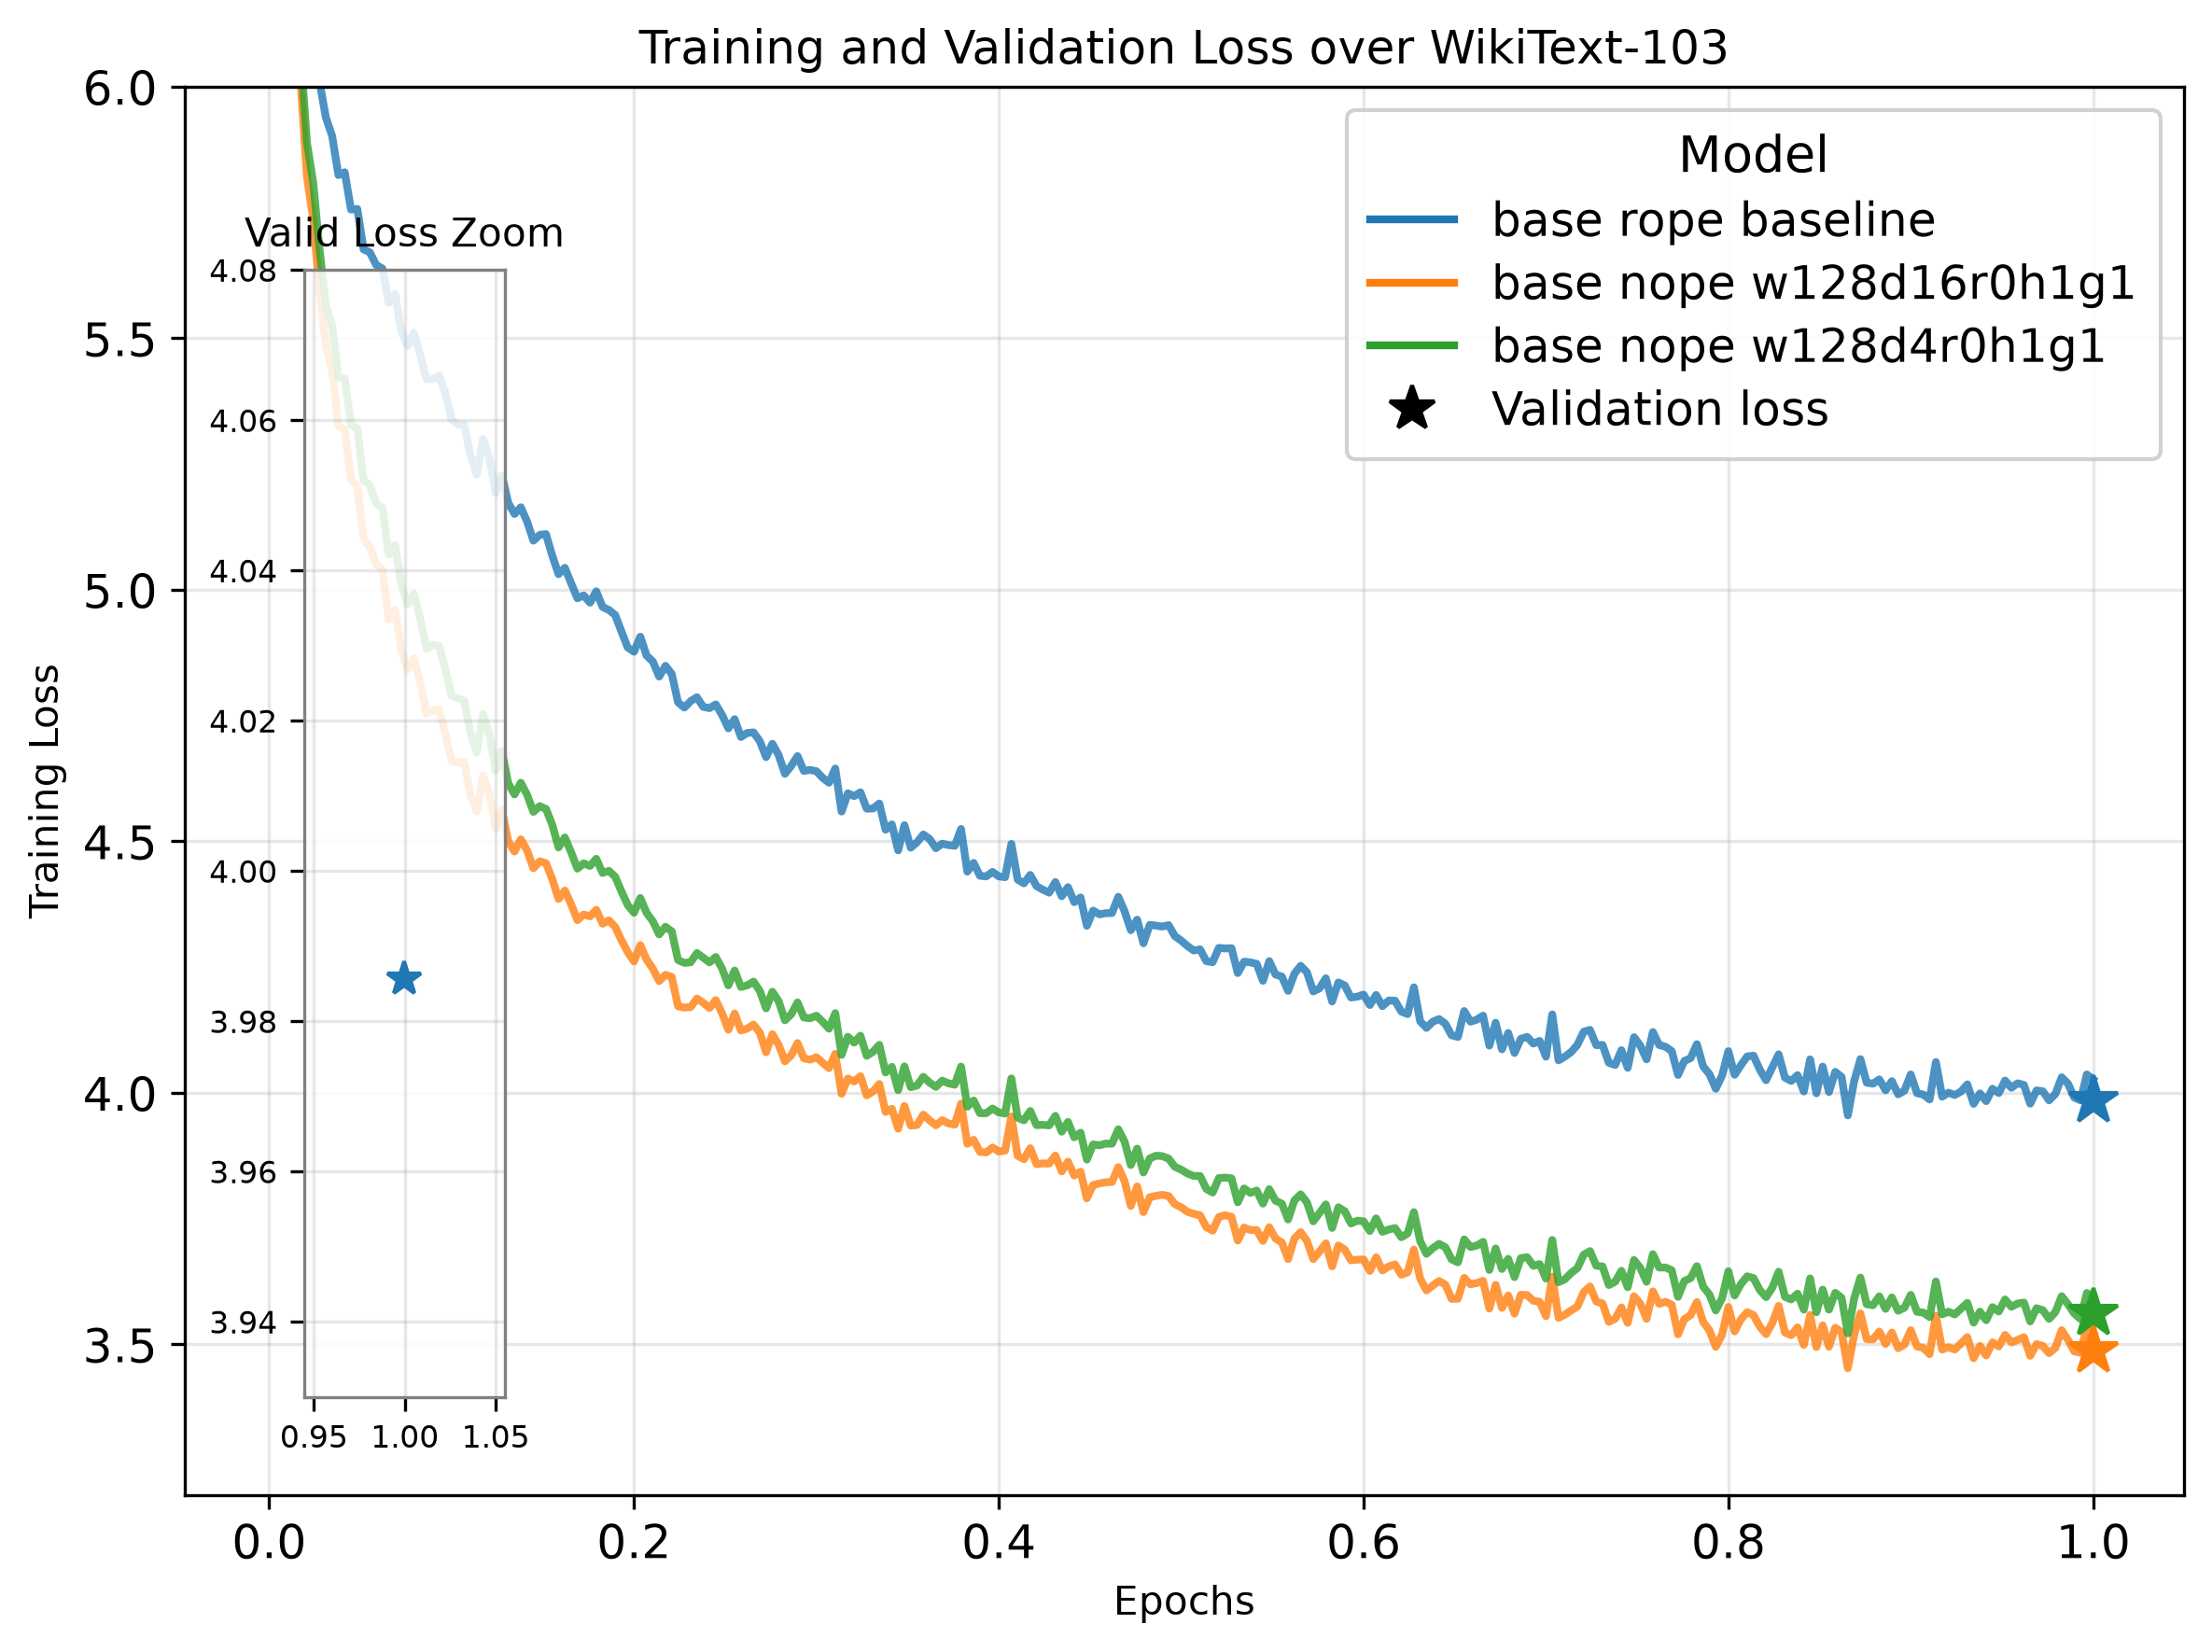

In [16]:
import os, re
import json
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ROOTS = ["results"]


def name_to_label(name):
    parts = name.split("_")
    base = " ".join(parts[0:-1]) if len(parts) > 1 else name
    return {}.get(base, base)


def read_trainer_state(ckpt_dir):
    path = os.path.join(ckpt_dir, "trainer_state.json")
    if not os.path.isfile(path):
        return None
    with open(path) as f:
        return json.load(f)


def read_eval_results(ckpt_dir):
    path = os.path.join(ckpt_dir, "../eval_results.txt")
    if not os.path.isfile(path):
        return None
    with open(path) as f:
        text = f.read()
    m = re.search(r"loss\s*=\s*([\d.]+)", text)
    return float(m.group(1)) if m else None


def find_latest_checkpoint(folder):
    ckpts = sorted(
        (int(m.group(1)), d)
        for d in os.listdir(folder)
        if (m := re.fullmatch(r"checkpoint-(\d+)", d))
        and os.path.isdir(os.path.join(folder, d))
    )
    return ckpts[-1][1] if ckpts else None


def find_latest_state(folder):
    ckpt = find_latest_checkpoint(folder)
    if ckpt is None:
        return None
    return read_trainer_state(os.path.join(folder, ckpt))


# ---------- 自动收集所有候选文件夹 ----------
folders = []
for root in ROOTS:
    if not os.path.isdir(root):
        print(f"[WARN] 根目录不存在: {root}")
        continue
    folders += sorted(
        os.path.join(root, d)
        for d in os.listdir(root)
        if os.path.isdir(os.path.join(root, d)) and not d.startswith(".")
    )

# 按字符排序，含 "baseline" 的排最上面
folders = sorted(
    folders,
    key=lambda p: (0 if "baseline" in os.path.basename(p).lower() else 1, p),
)

if not folders:
    raise SystemExit("没有找到任何候选文件夹，请检查 ROOTS 设置。")

# ---------- 绘图 ----------
fig, ax = plt.subplots(figsize=(8, 6), dpi=300)
colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

model_handles, model_labels = [], []
eval_records = []  # [(label, color, [(epoch, eval_loss), ...]), ...]

for folder in folders:
    folder = folder.rstrip("/")
    name = os.path.basename(folder)
    if not name.startswith("base"):
        continue
    label = name_to_label(name)

    state = find_latest_state(folder)
    if not state:
        continue

    train_pts = sorted(
        (e["epoch"], e["loss"])
        for e in state.get("log_history", [])
        if "loss" in e and "eval_loss" not in e and "epoch" in e
    )
    if not train_pts:
        continue

    color = colors[len(model_handles) % len(colors)]
    ax.plot(
        [p[0] for p in train_pts],
        [p[1] for p in train_pts],
        lw=2.0,
        alpha=0.8,
        color=color,
        linestyle="-",
    )

    # eval loss 点（同色星星）
    eval_pts = sorted(
        (e["epoch"], e["eval_loss"])
        for e in state.get("log_history", [])
        if "eval_loss" in e and "epoch" in e
    )
    if not eval_pts:
        ckpt = find_latest_checkpoint(folder)
        ev = read_eval_results(os.path.join(folder, ckpt)) if ckpt else None
        if ev is not None:
            eval_pts = [(train_pts[-1][0], ev)]

    if eval_pts:
        ax.plot(
            [p[0] for p in eval_pts],
            [p[1] for p in eval_pts],
            linestyle="none",
            marker="*",
            markersize=13,
            color=color,
            zorder=5,
        )
        eval_records.append((label, color, eval_pts))

    model_handles.append(Line2D([0], [0], color=color, lw=2.0))
    model_labels.append(label)

if not model_handles:
    raise SystemExit("所有文件夹都没有可用数据，未绘制任何曲线。")

# ---------- 左下角 inset：放大 validation loss ----------
if eval_records:
    # [x0, y0, width, height] 相对于主图 axes (0~1)，左下角
    inset = ax.inset_axes([0.06, 0.07, 0.1, 0.8])

    for label, color, pts in eval_records:
        xs = [p[0] for p in pts]
        ys = [p[1] for p in pts]
        if len(pts) >= 2:
            inset.plot(xs, ys, lw=1.2, alpha=0.5, color=color, zorder=2)
        inset.plot(
            xs, ys, linestyle="none", marker="*", markersize=9, color=color, zorder=5
        )

    inset.set_title("Valid Loss Zoom", fontsize=10)
    inset.tick_params(labelsize=8)
    inset.grid(True, alpha=0.3)
    for spine in inset.spines.values():
        spine.set_edgecolor("gray")

    # 半透明白底，避免主图曲线透过
    inset.patch.set_facecolor("white")
    inset.patch.set_alpha(0.85)

    inset.set_ylim(3.93, 4.08)

# ---------- 图例 ----------
legend_handles = model_handles + [
    Line2D([0], [0], color="black", linestyle="none", marker="*", markersize=12)
]
legend_labels = model_labels + ["Validation loss"]

ax.legend(
    handles=legend_handles,
    labels=legend_labels,
    loc="upper right",
    title="Model",
    fontsize=12,
    framealpha=0.9,
    labelspacing=0.35,
    handlelength=1.8,
    borderpad=0.5,
    title_fontsize=13,
)

ax.set_xlabel("Epochs")
ax.set_ylabel("Training Loss")
ax.set_title("Training and Validation Loss over WikiText-103")
ax.set_ylim(3.2, 6)
ax.tick_params(labelsize=12)
ax.grid(True, alpha=0.3)
fig.tight_layout()

plt.show()